# Attention：读出被标记的数

目标：让网络从四个位置中读出带标记的数。每个位置有两个特征：数值，以及是否被标记。注意力会学习应该从哪些位置获取信息。

从项目根目录运行。`device` 可换为 `"cpu"` 或 `"cuda"`；不固定随机种子。

In [1]:
from qutai import Stream, nn, visualization

device = "apple"

## 1. 看数据

四个序列各有四种标记位置，共 16 个样本。目标就是标记所在位置的数，不需要下载数据。

In [2]:
sequences = [[-1, -0.5, 0.5, 1], [0.5, -1, 1, -0.5], [1, 0.5, -0.5, -1], [-0.5, 1, -1, 0.5]]
inputs = [[[value, int(index == marked)] for index, value in enumerate(values)] for values in sequences for marked in range(4)]
targets = [[values[marked]] for values in sequences for marked in range(4)]
sample = inputs[0]
print("这个序列的目标：", targets[0][0])
visualization.Table(sample, columns=["数值", "标记"])

这个序列的目标： -1


数值,标记
-1,1
-0.5,0
0.5,0
1,0


## 2. 搭模型

Attention 混合位置之间的信息，Linear 把特征变为一个数，Mean 将四个位置的结果汇总。热力图展示每个位置关注了哪里，每一行的权重之和为 1。

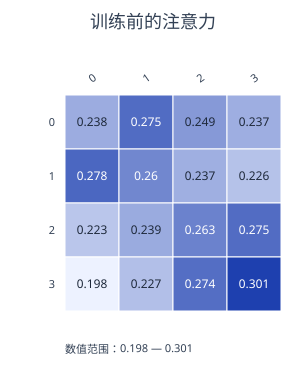

In [3]:
model = nn.Model([nn.Attention(2, 8), nn.Linear(8, 1), nn.Mean(axis=1)]).to(device)
optimizer = nn.AdamW(model, learning_rate=0.02)
loss_function = nn.MSE()
data = Stream(inputs, targets, batch_size=4, device=device, progress=False)

visualization.Heatmap(model.layers[0].weights([sample])[0].tolist(), title="训练前的注意力")

## 3. 训练

仍然使用同一套训练循环。梯度会同时更新 Attention 的 Q、K、V 投影以及最后的 Linear。

In [4]:
epochs = 50
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/50  loss 0.846850
epoch 2/50  loss 0.438581
epoch 3/50  loss 0.416125
epoch 4/50  loss 0.578489
epoch 5/50  loss 0.387667
epoch 6/50  loss 0.308697
epoch 7/50  loss 0.357947
epoch 8/50  loss 0.167480
epoch 9/50  loss 0.059840
epoch 10/50  loss 0.018398
epoch 11/50  loss 0.055216
epoch 12/50  loss 0.027325
epoch 13/50  loss 0.016649
epoch 14/50  loss 0.018938
epoch 15/50  loss 0.010670
epoch 16/50  loss 0.022984
epoch 17/50  loss 0.004413
epoch 18/50  loss 0.003704
epoch 19/50  loss 0.003358
epoch 20/50  loss 0.001790
epoch 21/50  loss 0.001003
epoch 22/50  loss 0.001048
epoch 23/50  loss 0.000678
epoch 24/50  loss 0.000216
epoch 25/50  loss 0.000652
epoch 26/50  loss 0.000411
epoch 27/50  loss 0.000282
epoch 28/50  loss 0.000111
epoch 29/50  loss 0.000111
epoch 30/50  loss 0.000101
epoch 31/50  loss 0.000186
epoch 32/50  loss 0.000123
epoch 33/50  loss 0.000043
epoch 34/50  loss 0.000028
epoch 35/50  loss 0.000043
epoch 36/50  loss 0.000044
epoch 37/50  loss 0.000008
epoch 38/5

## 4. 看结果

第一列带标记，观察它是否获得了较大的注意力。注意力权重展示信息如何混合，最终预测是否准确仍由数值误差判断。

目标： -1
预测： -1.0016696453094482


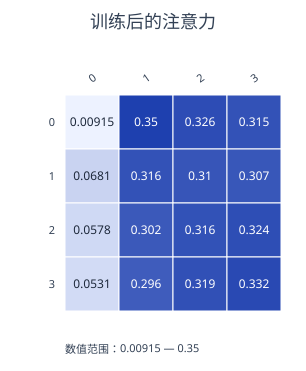

In [5]:
print("目标：", sequences[0][0])
print("预测：", model([sample], train=False).item())
visualization.Heatmap(model.layers[0].weights([sample])[0].tolist(), title="训练后的注意力")